## Detecting Outperformers

In [1]:
# Loading the data

from src.data.dataloader import load_data
from src.utils.paths import DATA_DIR
import os

In [2]:
# Load the pre-computed channels with efficiency scores.

channel_df = load_data(os.path.join(DATA_DIR, "channels_with_efficiency.tsv.gz"))
channel_df.head(5)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_id,avg_efficiency,avg_views,avg_duration,video_count
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,UC-lHJZR3Gqxm24_Vd_AJ5Yw,0.037864,5.971857e+06,878.499873,3927.0
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,UCbCmjCuTUZos6Inko4u57UQ,0.001860,9.358046e+07,1123.391775,462.0
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,UCpEhnqL0y41EpW2TvWAHD7Q,0.004200,1.705198e+06,1276.033720,23903.0
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,UC295-Dw_tDNtZXFeAPAW6Aw,0.009845,4.404196e+06,933.562086,3624.0
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,UCJ5v_MCY6GNUBTO8-D3XoAg,0.013796,8.939673e+05,194.059854,40549.0


### Identifying small to mid sized channels

To identify these sizes of channels, lets first look at the distribution of channels based on subscribers.

Since the subscriber count is heavy tailed along the higher number of subscribers we labeled small channels in 50%, and the mid sized channels from 50% to 90% of the channel distribution.

In [3]:
from src.utils.general_utils import weighted_percentiles, weighted_percentile_of_value

cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: np.float64(22200.0), 90: np.float64(160000.0)}


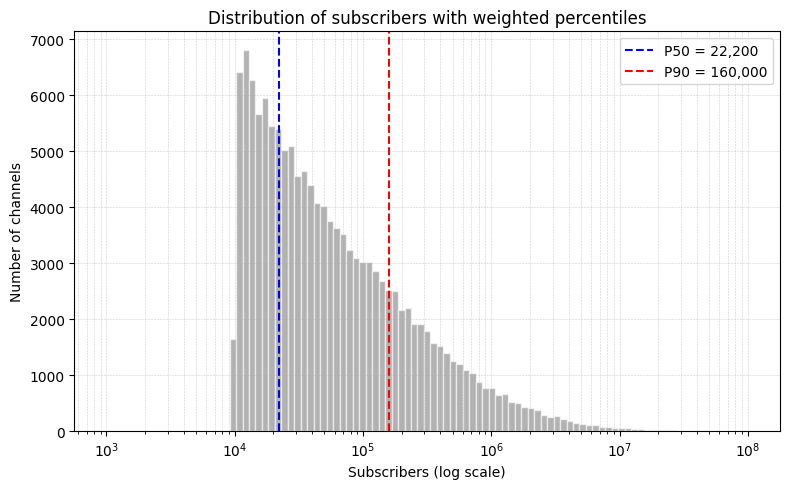

In [14]:
# Plotting this distribution to get a better feel
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,5))
plt.hist(
    channel_df["subscribers_cc"],
    bins=np.logspace(3, 8, 100),     # log-spaced bins from 1e3 to 1e8
    color="gray",
    alpha=0.6,
    edgecolor="white"
)
plt.axvline(p50, color="blue", linestyle="--", linewidth=1.5, label=f"P50 = {p50:,.0f}")
plt.axvline(p90, color="red", linestyle="--", linewidth=1.5, label=f"P90 = {p90:,.0f}")

plt.xscale("log")
plt.xlabel("Subscribers (log scale)")
plt.ylabel("Number of channels")
plt.title("Distribution of subscribers with weighted percentiles")
plt.grid(True, which="both", ls="--", lw=0.4, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Now we filter and keep the channels that are small to mid sized

#small_mid_sized_channels_df =channel_df[channel_df["subscribers_cc"] <= p90].copy()

small_mid_sized_channels_df =channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### Fitting the model and detecting the outperformers

**Engagement efficiency (video level):**
For each video *v* Engagement efficiency is defined as:
`E_v = (likes_v + comments_v) / views_v`

**Channel-level efficiency** is the average efficiency over all videos of a channel *c*:
`E_c = (Σ(likes_v + comments_v)) / Σ(views_v)`

**Expected efficiency model (log–log linear regression):**
We model how efficiency changes with channel size:
`log10(E_c) = a + b * log10(subscribers_c) + ε_c`
This stabilizes heavy-tailed data and makes the relationship roughly linear.

**Why log–log?**
YouTube metrics vary by orders of magnitude; logs reduce skew and make trends clearer.

**Residuals (deviation from expectation):**
`r_c = log10(E_c) - (a + b * log10(subscribers_c))`

**Quiet outperformers:**
Channels with residuals above a threshold γ (e.g., mean + 2·std or top 5%) are labeled as outperformers:
`if r_c > γ → quiet outperformer`



In [6]:
from src.models.log_log_efficiency_model import linear_log_log_model

channels_model = linear_log_log_model(
     df=small_mid_sized_channels_df,
     x_col="subscribers_cc",
     y_col="avg_efficiency",
     weight_col="weights",
     gamma_z=2.0,
     log_base=10,
     verbose=True,
    )

channels_model.head(5)

 log–log model fitted: log(y) = -1.1923 + -0.1014 * log(x)
   Outliers (z>2.0): 486/94227 (0.52%)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_id,avg_efficiency,avg_views,avg_duration,video_count,log_x,log_y,pred_log_y,residual,zscore,is_outlier
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,UC7wnYvoFWmX-Ad6Az7BsiDQ,0.058282,221217.875000,1171.062500,16.0,4.992111,-1.234465,-1.698242,0.463778,1.282523,False
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,UCCjlZHOg6TWQmJ4k3esGxCg,0.025255,152435.985019,266.838951,267.0,4.965202,-1.597647,-1.695515,0.097868,0.276204,False
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,UC5H8PC7IVxeicx5x5p8roWA,0.027180,286129.714286,306.228571,35.0,4.994242,-1.565754,-1.698458,0.132705,0.372011,False
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,UCDGY6cFaZKjlY1bguFZHdeQ,0.026783,393607.826923,692.423077,52.0,4.992120,-1.572146,-1.698243,0.126097,0.353841,False
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,UC5du0zGwGLWhMAJkLmltGpg,0.013217,246571.128571,622.471429,70.0,4.967548,-1.878871,-1.695753,-0.183118,-0.496558,False


In [7]:
outperformers = channels_model[channels_model["is_outlier"]]


print(len(outperformers))
outperformers.head(300)

486


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_id,avg_efficiency,avg_views,avg_duration,video_count,log_x,log_y,pred_log_y,residual,zscore,is_outlier
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,UCwpAYjmPdYVw6ZNoiul8g2Q,0.126679,22466.806630,378.497238,181.0,4.924538,-0.897296,-1.691394,0.794098,2.190962,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,UCkrkMMAyxC9vGNa6ZJYyscg,0.135340,66703.232353,269.752941,340.0,4.866878,-0.868574,-1.685550,0.816976,2.253880,True
36916,Sports,2018-12-07,UCfFQyv0h5WwZ_mu7YXYj31w,Chomno Bro Game,94700,255,127798.0,3.9435,UCfFQyv0h5WwZ_mu7YXYj31w,0.151615,19179.232558,774.290698,258.0,4.976350,-0.819258,-1.696645,0.877387,2.420022,True
41863,Entertainment,2019-01-01,UC4KvfbBBN-OJdLtog5IjZcQ,Baba ji ki Booty 2.0...,97000,54,150446.0,4.7970,UC4KvfbBBN-OJdLtog5IjZcQ,0.124459,145263.232143,311.857143,56.0,4.986772,-0.904974,-1.697701,0.792727,2.187192,True
41874,People & Blogs,2019-03-17,UCZLYgdpGVPcDjPTej4LiAYw,Manpreet Singh,86376,17,150494.0,4.7955,UCZLYgdpGVPcDjPTej4LiAYw,0.156510,213960.470588,421.823529,17.0,4.936393,-0.805457,-1.692595,0.887138,2.446840,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110614,Entertainment,2011-03-06,UCIvMXWaKOpG5vhe93An0QRw,Charlotte Crumpton,17700,157,647739.0,10.2775,UCIvMXWaKOpG5vhe93An0QRw,0.175232,6360.189542,419.843137,153.0,4.247973,-0.756386,-1.622823,0.866437,2.389907,True
110882,Gaming,2016-07-23,UCLI3b1mnwxkJjOPnEWbFfCQ,Scriv,18000,433,649537.0,9.8150,UCLI3b1mnwxkJjOPnEWbFfCQ,0.161838,624.215278,6996.807870,432.0,4.255273,-0.790919,-1.623563,0.832644,2.296971,True
110955,Science & Technology,2016-11-29,UCsEtJ6VcUck6lfSwFENW8ug,Majestic NISARG,17200,143,649949.0,9.6360,UCsEtJ6VcUck6lfSwFENW8ug,0.134577,6103.178082,220.239726,146.0,4.235528,-0.871028,-1.621562,0.750534,2.071153,True
111178,Music,2012-11-05,UC-YkQGu7T-yBxOx9vbHCgtw,PhilippaHanna,17000,418,652016.0,9.1140,UC-YkQGu7T-yBxOx9vbHCgtw,0.130768,5820.071942,230.410072,417.0,4.230449,-0.883498,-1.621047,0.737549,2.035442,True


In [8]:
outperformers = channels_model[channels_model["is_outlier"]].sort_values(by="subscribers_cc", ascending=True)

print(len(outperformers))
outperformers.head(300)

486


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_id,avg_efficiency,avg_views,avg_duration,video_count,log_x,log_y,pred_log_y,residual,zscore,is_outlier
133454,Gaming,2016-05-22,UC-3UK-xM8oBJuYp1T0YB7Pg,Resqwad,10000,397,906030.0,14.9640,UC-3UK-xM8oBJuYp1T0YB7Pg,0.137797,251.863980,2742.168766,397.0,4.000000,-0.860759,-1.597691,0.736931,2.033744,True
133897,Science & Technology,2012-11-14,UC-sQ0P6uSCe3vqWmzN_WSBw,DudetECH,10000,556,916328.0,16.3215,UC-sQ0P6uSCe3vqWmzN_WSBw,0.220348,4622.850615,449.483304,569.0,4.000000,-0.656891,-1.597691,0.940800,2.594419,True
132399,Entertainment,2015-12-25,UCsyIJO2LrJUIkaXf9CPPbaA,endervurse,10000,258,892344.0,14.0825,UCsyIJO2LrJUIkaXf9CPPbaA,0.136435,12546.348837,835.709302,258.0,4.000000,-0.865073,-1.597691,0.732617,2.021879,True
134651,Gaming,2018-01-10,UC01BXM3HTneoEiimOKj5j2g,SuperNova GamePro Gi...,10000,187,927075.0,21.2005,UC01BXM3HTneoEiimOKj5j2g,0.163522,783.770053,145.839572,187.0,4.000000,-0.786423,-1.597691,0.811267,2.238181,True
121498,Entertainment,2016-04-04,UCUAnj7ldwgo4zaXe2-8uR7w,ActionFeature,10000,17,759799.0,11.8625,UCUAnj7ldwgo4zaXe2-8uR7w,0.135260,6696.062500,4162.812500,16.0,4.000000,-0.868831,-1.597691,0.728859,2.011544,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91618,Entertainment,2018-09-27,UCnmUbhYf3Em7ZgNjNvbvDTA,Yasmin Brossi,23400,12,474216.0,8.1800,UCnmUbhYf3Em7ZgNjNvbvDTA,0.132125,20732.250000,732.916667,12.0,4.369216,-0.879014,-1.635111,0.756097,2.086452,True
92113,Gaming,2017-02-09,UC_JkXZQMbUTlH7M3vyf1eTQ,Farewell Games SFM,23400,487,477609.0,9.2240,UC_JkXZQMbUTlH7M3vyf1eTQ,0.228785,15842.922290,1269.042945,489.0,4.369216,-0.640572,-1.635111,0.994539,2.742212,True
96371,Gaming,2014-11-10,UCKg-TguylQlNFD8XCb3b4mQ,Dope Boy Taeひ,23700,201,512413.0,9.1660,UCKg-TguylQlNFD8XCb3b4mQ,0.124856,5912.520833,176.885417,192.0,4.374748,-0.903590,-1.635672,0.732082,2.020407,True
95747,Entertainment,2019-03-28,UC44U2t5oToWw1Des3oF1BPg,『FBi』 LEADER,23831,59,507995.0,7.1505,UC44U2t5oToWw1Des3oF1BPg,0.142738,4385.742857,5603.800000,35.0,4.377142,-0.845459,-1.635914,0.790455,2.180943,True


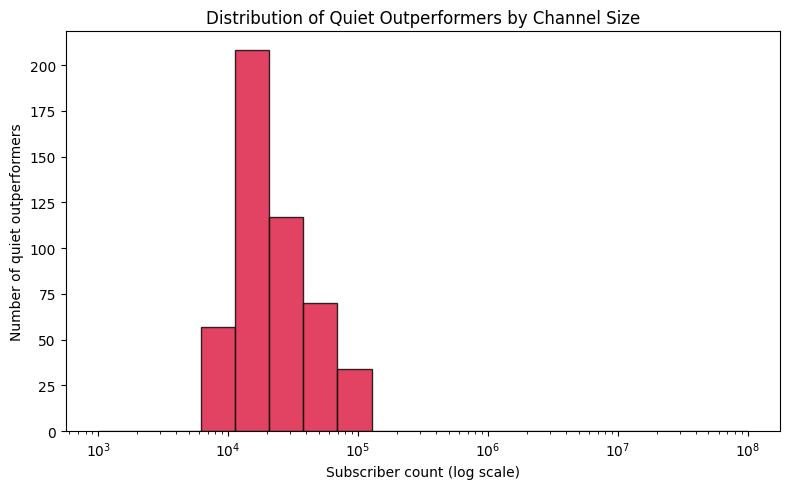

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def plot_outperformer_distribution(df, subscribers_col="subscribers_cc", outperformer_col="is_outlier",
                                   bins=None, log_scale=True):
    """
    Plot the distribution of quiet outperformers across subscriber count ranges.

    X-axis: subscriber count (binned)
    Y-axis: number of outperformers in each bin
    """

    # Default: log-spaced bins from 1k to 100M subs
    if bins is None:
        bins = np.logspace(3, 8, 20)

    # Filter valid
    valid = df[df[subscribers_col] > 0]
    outp = valid[valid[outperformer_col]]

    # Histogram of outperformers
    counts, bin_edges = np.histogram(outp[subscribers_col], bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.figure(figsize=(8,5))
    plt.bar(centers, counts, width=np.diff(bin_edges), align="center",
            alpha=0.8, edgecolor="black", color="crimson")

    if log_scale:
        plt.xscale("log")

    plt.xlabel("Subscriber count (log scale)")
    plt.ylabel("Number of quiet outperformers")
    plt.title("Distribution of Quiet Outperformers by Channel Size")
    plt.tight_layout()
    plt.show()


plot_outperformer_distribution(channels_model)

In [4]:
from src.utils.general_utils import weighted_percentile_of_value

p_1m = weighted_percentile_of_value(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    1_000_000
)
print(f"1M subscribers ≈ {p_1m:.2f}th percentile")

p_100k = weighted_percentile_of_value(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    1_00_000
)

print(f"100k subscribers ≈ {p_100k:.2f}th percentile")

1M subscribers ≈ 98.49th percentile
100k subscribers ≈ 84.87th percentile
